## Setup

In [1]:
!pip install -q mediapipe tqdm

In [2]:
import os, json, shutil, zipfile, requests, warnings, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 200); pd.set_option('display.width', 200)

DATA_DIR = '/content/data'
ROOT = os.path.join(DATA_DIR, 'Pakistan Sign Language Urdu Alphabets')
OUT = '/content/outputs'; IMG_OUT = os.path.join(OUT, 'images'); PROC = '/content/processed'
os.makedirs(IMG_OUT, exist_ok=True); os.makedirs(PROC, exist_ok=True)

# Re-download the raw dataset only if the Colab runtime was reset
if not os.path.isdir(ROOT):
    ZIP_PATH = '/content/ualpha40.zip'
    URL = 'https://data.mendeley.com/public-api/zip/3pvnnckxyb/download/1'
    if not os.path.exists(ZIP_PATH):
        with requests.get(URL, stream=True) as r:
            r.raise_for_status()
            with open(ZIP_PATH, 'wb') as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

# Upload clean_metadata.csv and channel_stats.json
need = ['clean_metadata.csv', 'channel_stats.json']
if not all(os.path.exists('/content/' + f) for f in need):
    from google.colab import files
    files.upload()

def savefig(name):
    plt.savefig(os.path.join(IMG_OUT, name), dpi=130, bbox_inches='tight')

Saving channel_stats.json to channel_stats.json
Saving clean_metadata.csv to clean_metadata.csv


## 1. Load data and configuration

In [3]:
IMG_SIZE = 224          # EfficientNet-B0 input size
SPLIT_RATIOS = (0.70, 0.15, 0.15)
SEED = 42

df = pd.read_csv('/content/clean_metadata.csv')
df['path'] = df['rel_path'].map(lambda p: os.path.join(ROOT, p))
imgs = df[df['media_type'] == 'image'].copy().reset_index(drop=True)
vids = df[df['media_type'] == 'video'].copy().reset_index(drop=True)
imgs['is_generated'] = imgs['is_generated'].astype(bool)
imgs['aspect'] = imgs['width'] / imgs['height']
eda_stats = json.load(open('/content/channel_stats.json'))

STATIC = sorted(imgs['label'].unique()); DYNAMIC = sorted(vids['label'].unique())
ALL_LABELS = STATIC + DYNAMIC                      # static ids 0-35, dynamic ids 36-39
label2id = {c: i for i, c in enumerate(ALL_LABELS)}
imgs['class_id'] = imgs['label'].map(label2id); vids['class_id'] = vids['label'].map(label2id)
print('Images:', len(imgs), '| Videos:', len(vids), '| classes:', len(ALL_LABELS))
print('Video filenames carry a subject id for', f"{vids['subject'].notna().mean():.0%}", 'of videos')

Images: 21360 | Videos: 393 | classes: 40
Video filenames carry a subject id for 0% of videos


## 2. Resize policy
Images have mixed orientation and very different resolutions (from the EDA), but the network needs a fixed square input. Three options are compared on the most extreme aspect ratios:
- **Stretch**: distorts the hand shape
- **Center crop**: can cut off fingers, which are exactly what distinguishes letters
- **Pad to square** (keep aspect ratio, fill the border with the dataset mean colour): nothing is distorted or lost

The fill colour is the dataset mean colour, so after normalization the padding is approximately zero.

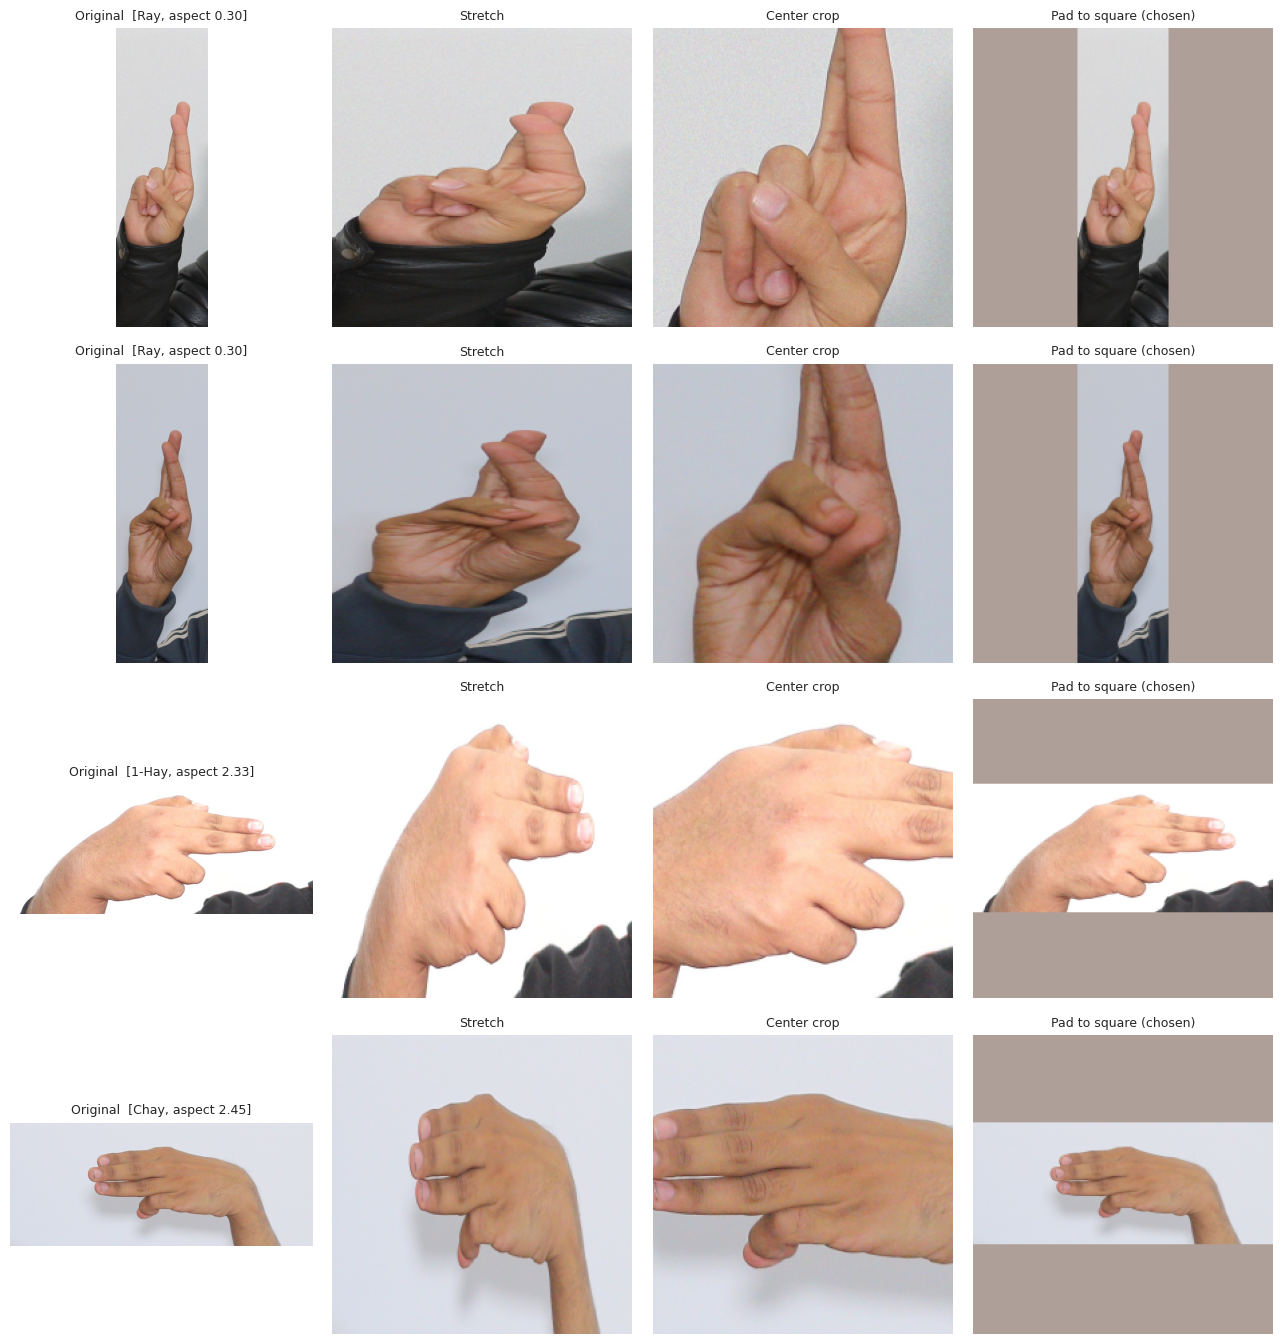

In [4]:
fill_rgb = (np.array(eda_stats['rgb_mean']) * 255).round().astype(np.uint8)
fill_bgr = fill_rgb[::-1].copy()

def resize_pad(img, size=IMG_SIZE, fill=fill_bgr):
    h, w = img.shape[:2]; s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    r = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    canvas = np.empty((size, size, 3), np.uint8); canvas[:] = fill
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = r
    return canvas

def stretch(img, size=IMG_SIZE): return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
def center_crop(img, size=IMG_SIZE):
    h, w = img.shape[:2]; m = min(h, w); t, l = (h - m) // 2, (w - m) // 2
    return cv2.resize(img[t:t + m, l:l + m], (size, size), interpolation=cv2.INTER_AREA)

srt = imgs.sort_values('aspect')
demo = pd.concat([srt.head(2), srt.tail(2)])            # 2 most portrait + 2 most landscape
fig, axes = plt.subplots(len(demo), 4, figsize=(13, 3.4 * len(demo)))
for r, (_, row) in enumerate(demo.iterrows()):
    im = cv2.imread(row['path'])
    for k, (ttl, fn) in enumerate([('Original', lambda x: x), ('Stretch', stretch), ('Center crop', center_crop), ('Pad to square (chosen)', resize_pad)]):
        axes[r, k].imshow(cv2.cvtColor(fn(im), cv2.COLOR_BGR2RGB)); axes[r, k].axis('off')
        axes[r, k].set_title(f"{ttl}" + (f"  [{row['label']}, aspect {row['aspect']:.2f}]" if k == 0 else ''), fontsize=9)
plt.tight_layout(); savefig('16_resize_policy_comparison.png'); plt.show()

**What it tells us:** on the extreme images, stretching visibly deforms the hand and center-cropping can lose fingers at the edge, while padding keeps the whole hand with correct proportions. **Decision: pad to a 224×224 square.** The cost is some empty border on very wide or tall images, which is acceptable.

## 3. Subject-wise train / validation / test split


In [5]:
def best_group_split(mats, ratios=SPLIT_RATIOS, n_seeds=1000):
    S = mats[0].shape[0]; n_tr = int(round(ratios[0] * S)); n_va = int(round(ratios[1] * S))
    tots = [m.sum(0).astype(float) for m in mats]
    best = (9e9, None, None)
    for seed in range(n_seeds):
        perm = np.random.RandomState(seed).permutation(S)
        a = np.zeros(S, int); a[perm[n_tr:n_tr + n_va]] = 1; a[perm[n_tr + n_va:]] = 2
        dev = max(np.abs(m[a == k].sum(0) / np.maximum(t, 1) - ratios[k]).max() for m, t in zip(mats, tots) for k in range(3))
        if dev < best[0]: best = (dev, seed, a)
    return best

all_m = imgs.groupby(['subject', 'label']).size().unstack(fill_value=0)
orig_m = imgs[~imgs['is_generated']].groupby(['subject', 'label']).size().unstack(fill_value=0).reindex(index=all_m.index, columns=all_m.columns, fill_value=0)
dev, seed_used, assign = best_group_split([all_m.values, orig_m.values])
SPLITS = ['train', 'val', 'test']
subj2split = dict(zip(all_m.index, [SPLITS[a] for a in assign]))
imgs['split'] = imgs['subject'].map(subj2split)
print(f'Subjects: {len(all_m)} | best seed = {seed_used} | worst per-class deviation from target = {dev:.3f}')
print('Subjects per split:', pd.Series(subj2split).value_counts().to_dict())

Subjects: 84 | best seed = 743 | worst per-class deviation from target = 0.029
Subjects per split: {'train': 59, 'val': 13, 'test': 12}


In [6]:
# Videos: split by subject if the filenames carry one, otherwise a stratified random split
vids['split'] = None
subj_ok = vids['subject'].notna().all() and vids['subject'].nunique() >= 10
if subj_ok:
    vm = vids.groupby(['subject', 'label']).size().unstack(fill_value=0)
    vdev, vseed, vassign = best_group_split([vm.values])
    vids['split'] = vids['subject'].map(dict(zip(vm.index, [SPLITS[a] for a in vassign])))
    VIDEO_SPLIT_MODE = f'by subject ({vm.shape[0]} subjects), worst deviation {vdev:.3f}'
else:
    tr, tmp = train_test_split(vids.index, test_size=0.30, stratify=vids['label'], random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=vids.loc[tmp, 'label'], random_state=SEED)
    vids.loc[tr, 'split'] = 'train'; vids.loc[va, 'split'] = 'val'; vids.loc[te, 'split'] = 'test'
    VIDEO_SPLIT_MODE = 'stratified random (no usable subject id in video filenames)'
print('Video split mode:', VIDEO_SPLIT_MODE)
print(pd.crosstab(vids['label'], vids['split']))

Video split mode: stratified random (no usable subject id in video filenames)
split    test  train  val
label                    
2-Hay      13     61   13
Alifmad    16     74   15
Aray       15     71   16
Jeem       15     69   15


### 3.1 Validate the split

OK: no subject overlaps between train / val / test
OK: every static class appears in every split
Per-class share of images: min / max per split
split  train    val   test
min    0.677  0.126  0.123
max    0.729  0.168  0.173

Original-only images per split: {'train': 2028, 'val': 439, 'test': 430}
Generated share per split: {'test': 0.867, 'train': 0.865, 'val': 0.857}
Totals: {'train': 15062, 'val': 3060, 'test': 3238}


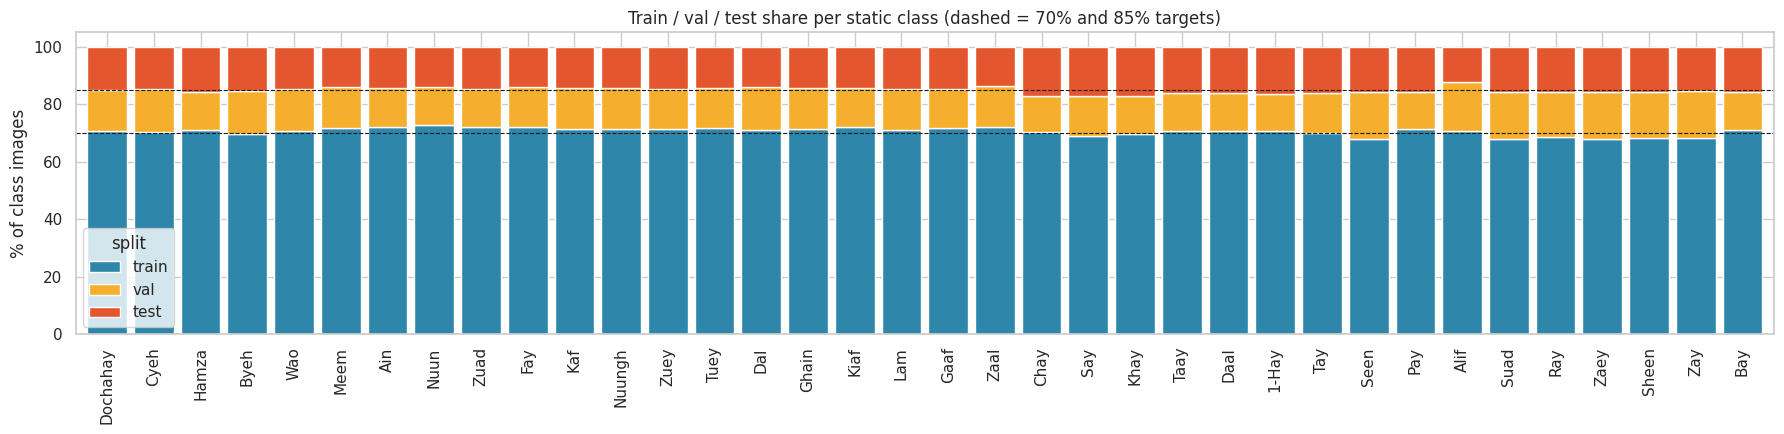

In [7]:
# 1. no subject appears in two splits
sets = {s: set(imgs.loc[imgs['split'] == s, 'subject']) for s in SPLITS}
assert not (sets['train'] & sets['val'] or sets['train'] & sets['test'] or sets['val'] & sets['test']), 'LEAKAGE: subject in two splits'
print('OK: no subject overlaps between train / val / test')

# 2. every class present in every split; sizes
ct = pd.crosstab(imgs['label'], imgs['split'])[SPLITS]
assert (ct > 0).all().all(); print('OK: every static class appears in every split')
share = ct.div(ct.sum(1), axis=0)
print('Per-class share of images: min / max per split'); print(pd.DataFrame({'min': share.min(), 'max': share.max()}).round(3).T.to_string())
orig_ct = pd.crosstab(imgs[~imgs['is_generated']]['label'], imgs[~imgs['is_generated']]['split'])[SPLITS]
print('\nOriginal-only images per split:', orig_ct.sum().to_dict())
print('Generated share per split:', imgs.groupby('split')['is_generated'].mean().round(3).to_dict())
print('Totals:', ct.sum().to_dict())

fig, ax = plt.subplots(figsize=(18, 4.5))
(share.loc[ct.sum(1).sort_values().index] * 100).plot(kind='bar', stacked=True, ax=ax, color=['#2E86AB', '#F6AE2D', '#E4572E'], width=0.85)
ax.axhline(70, color='k', ls='--', lw=.8); ax.axhline(85, color='k', ls='--', lw=.8)
ax.set_ylabel('% of class images'); ax.set_xlabel(''); ax.set_title('Train / val / test share per static class (dashed = 70% and 85% targets)')
plt.tight_layout(); savefig('17_split_distribution.png'); plt.show()

**What it tells us:** every class sits close to the 70 / 15 / 15 target, so the validation and test sets have a similar class mix to training. The assertion above proves no person appears in more than one split. We can additionally report test results on original-only images, which is the most realistic estimate of real-world performance.

## 4. Label maps and class weights
Weights are computed from the **training split only**, using the standard balanced formula `n_samples / (n_classes × n_class_samples)`.

In [8]:
def balanced_weights(y_train, class_ids):
    counts = pd.Series(y_train).value_counts().reindex(class_ids, fill_value=0)
    return (len(y_train) / (len(class_ids) * counts)).round(4)

tr_img = imgs[imgs['split'] == 'train']; tr_vid = vids[vids['split'] == 'train']
w_static = balanced_weights(tr_img['class_id'], [label2id[c] for c in STATIC])
w_dyn = balanced_weights(tr_vid['class_id'], [label2id[c] for c in DYNAMIC])
print('Static weights: min', w_static.min(), '| max', w_static.max())
print('Dynamic weights:', {c: float(w_dyn[label2id[c]]) for c in DYNAMIC})

json.dump({'label2id': label2id, 'static_classes': STATIC, 'dynamic_classes': DYNAMIC}, open(os.path.join(OUT, 'label_map.json'), 'w'), indent=1)
json.dump({'static': {str(k): float(v) for k, v in w_static.items()}, 'dynamic': {str(k): float(v) for k, v in w_dyn.items()}},
          open(os.path.join(OUT, 'class_weights.json'), 'w'), indent=1)

Static weights: min 0.868 | max 1.1157
Dynamic weights: {'2-Hay': 1.127, 'Alifmad': 0.9291, 'Aray': 0.9683, 'Jeem': 0.9964}


## 5. Generate processed images (224×224, padded)


In [9]:
def process_one(row):
    dst_dir = os.path.join(PROC, row['split'], row['label'])
    dst = os.path.join(dst_dir, os.path.splitext(os.path.basename(row['path']))[0] + '.jpg')
    if not os.path.exists(dst):
        os.makedirs(dst_dir, exist_ok=True)
        im = cv2.imread(row['path'])
        cv2.imwrite(dst, resize_pad(im), [cv2.IMWRITE_JPEG_QUALITY, 95])
    return os.path.relpath(dst, PROC)

rows = imgs[['path', 'split', 'label']].to_dict('records')
with ThreadPoolExecutor(max_workers=8) as ex:
    imgs['processed_path'] = list(tqdm(ex.map(process_one, rows), total=len(rows)))

# verification
n_files = sum(len(f) for _, _, f in os.walk(PROC))
chk = imgs.sample(20, random_state=0)['processed_path']
assert all(cv2.imread(os.path.join(PROC, p)).shape == (IMG_SIZE, IMG_SIZE, 3) for p in chk)
print('Processed files:', n_files, '| expected:', len(imgs), '| sample shape check OK')

  0%|          | 0/21360 [00:00<?, ?it/s]

Processed files: 21360 | expected: 21360 | sample shape check OK


## 6. Normalization statistics (training split only)
Computed on processed *training* images only, so no information from validation or test leaks into preprocessing. Pixels are stored as uint8 and normalized in the data pipeline at training time. Three conventions are supported, depending on the backbone:
- `dataset`: `(x/255 − mean) / std` with the statistics below
- `mobilenetv2`: `x/127.5 − 1` (what Keras MobileNetV2 expects)
- `efficientnet`: raw 0–255 (Keras EfficientNet-B0 normalizes inside the model)

In [11]:
tr_img = imgs[imgs['split'] == 'train']

def load_proc(p):
    im = cv2.cvtColor(cv2.imread(os.path.join(PROC, p)), cv2.COLOR_BGR2RGB)
    return im

samp = tr_img.sample(min(3000, len(tr_img)), random_state=0)['processed_path'].tolist()
s1 = np.zeros(3); s2 = np.zeros(3); npx = 0
with ThreadPoolExecutor(max_workers=8) as ex:
    for im in tqdm(ex.map(load_proc, samp), total=len(samp)):
        x = im.reshape(-1, 3).astype(np.float64) / 255.0
        s1 += x.sum(0); s2 += (x ** 2).sum(0); npx += len(x)
train_mean = s1 / npx; train_std = np.sqrt(s2 / npx - train_mean ** 2)
print('Train RGB mean:', train_mean.round(4).tolist()); print('Train RGB std :', train_std.round(4).tolist())
print('EDA (all-image, stretch) mean:', np.round(eda_stats['rgb_mean'], 4).tolist())
json.dump({'rgb_mean': train_mean.tolist(), 'rgb_std': train_std.tolist(), 'n_images': len(samp), 'size': IMG_SIZE, 'split': 'train'},
          open(os.path.join(OUT, 'channel_stats_train.json'), 'w'), indent=1)

def normalize(x_uint8, mode='dataset'):
    x = x_uint8.astype(np.float32)
    if mode == 'dataset':      return (x / 255.0 - train_mean.astype(np.float32)) / train_std.astype(np.float32)
    if mode == 'mobilenetv2':  return x / 127.5 - 1.0
    if mode == 'efficientnet': return x
    raise ValueError(mode)

  0%|          | 0/3000 [00:00<?, ?it/s]

Train RGB mean: [0.6892, 0.6248, 0.6012]
Train RGB std : [0.2112, 0.23, 0.2432]
EDA (all-image, stretch) mean: [0.6878, 0.6238, 0.6011]


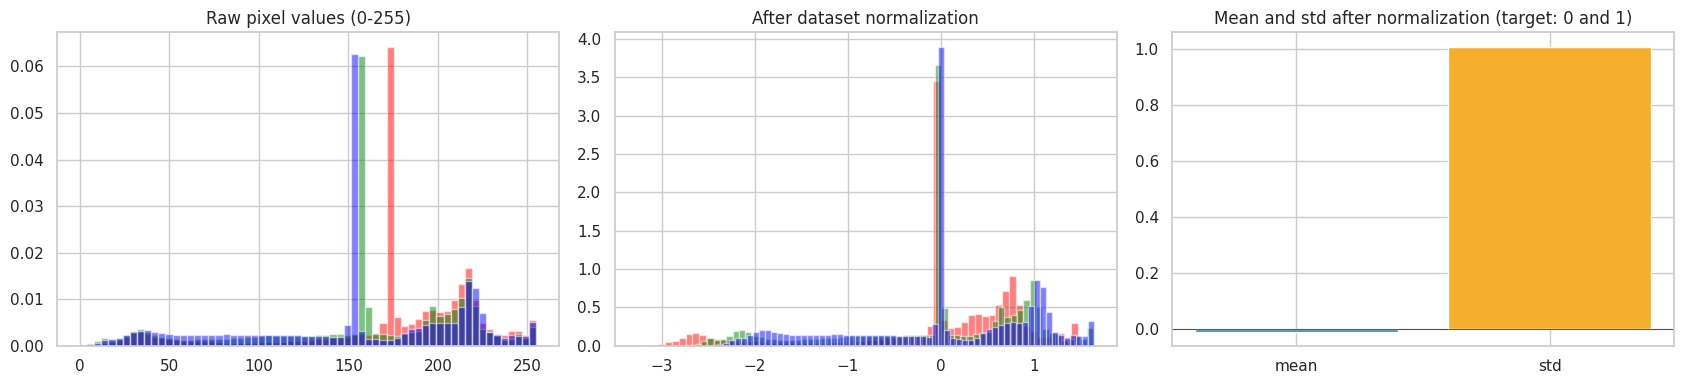

After normalization -> mean: -0.01 | std: 1.007


In [12]:
# Before / after normalization on 300 training images
batch = np.stack([load_proc(p) for p in tr_img.sample(300, random_state=1)['processed_path']])
normed = normalize(batch, 'dataset')
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for c, col in enumerate(['red', 'green', 'blue']):
    axes[0].hist(batch[..., c].ravel(), bins=64, alpha=.5, color=col, density=True)
    axes[1].hist(normed[..., c].ravel(), bins=64, alpha=.5, color=col, density=True)
axes[0].set_title('Raw pixel values (0-255)'); axes[1].set_title('After dataset normalization')
axes[2].bar(['mean', 'std'], [normed.mean(), normed.std()], color=['#2E86AB', '#F6AE2D']); axes[2].axhline(0, color='k', lw=.5)
axes[2].set_title('Mean and std after normalization (target: 0 and 1)')
plt.tight_layout(); savefig('18_normalization_before_after.png'); plt.show()
print('After normalization -> mean:', round(float(normed.mean()), 3), '| std:', round(float(normed.std()), 3))

**What it tells us:** raw pixels are concentrated in a narrow, bright band (the backgrounds are light). After normalization all three channels are centred at about 0 with a spread of about 1, which makes optimisation easier and matches what pretrained backbones expect.

## 7. Dynamic signs: landmark sequences for the LSTM
For each video: (1) pick a fixed number of frames `T` (the 95th percentile of training video lengths, rounded up to a multiple of 8) by uniform resampling, (2) detect the hand with MediaPipe in each frame, (3) keep the 21 landmarks (x, y, z) and **normalize** them: shift so the wrist is the origin and divide by the largest wrist-to-landmark distance. This removes hand position and hand size, so the model sees only the *shape and motion* of the hand. Frames with no detected hand become zeros, and a mask records which frames were detected.

In [13]:
train_frames = vids.loc[vids['split'] == 'train', 'frames']
T = int(np.ceil(train_frames.quantile(0.95) / 8) * 8)
print('Frames per video (train) 50/95/max:', train_frames.quantile(.5), train_frames.quantile(.95), train_frames.max(), '-> sequence length T =', T)

X_dyn = M_dyn = None
try:
    import mediapipe as mp
    from mediapipe.tasks import python as mp_python
    from mediapipe.tasks.python import vision
    MODEL = '/content/hand_landmarker.task'
    if not os.path.exists(MODEL):
        urllib.request.urlretrieve('https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task', MODEL)
    landmarker = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL), running_mode=vision.RunningMode.IMAGE,
        num_hands=1, min_hand_detection_confidence=0.5))

    def frame_landmarks(bgr):
        h, w = bgr.shape[:2]
        rgb = np.ascontiguousarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
        if not res.hand_landmarks: return None
        a = np.array([[p.x * w, p.y * h, p.z * w] for p in res.hand_landmarks[0]], np.float32)
        a -= a[0]
        sc = np.linalg.norm(a[:, :2], axis=1).max()
        return (a / sc).ravel() if sc > 1e-6 else None

    def video_sequence(path):
        cap = cv2.VideoCapture(path); frames = []
        while True:
            ok_, fr = cap.read()
            if not ok_: break
            s = 480 / max(fr.shape[:2])
            frames.append(cv2.resize(fr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else fr)
        cap.release()
        idx = np.linspace(0, len(frames) - 1, T).round().astype(int)
        seq = np.zeros((T, 63), np.float32); mask = np.zeros(T, bool); cache = {}
        for t, i in enumerate(idx):
            if i not in cache: cache[i] = frame_landmarks(frames[i])
            if cache[i] is not None: seq[t] = cache[i]; mask[t] = True
        return seq, mask

    out = [video_sequence(p) for p in tqdm(vids['path'], desc='videos')]
    X_dyn = np.stack([o[0] for o in out]); M_dyn = np.stack([o[1] for o in out])
    print('Landmark tensor:', X_dyn.shape, '| mean detected-frame rate:', round(float(M_dyn.mean()), 3))
except Exception as e:
    print('Landmark extraction skipped:', repr(e))

Frames per video (train) 50/95/max: 55.0 85.0 118.0 -> sequence length T = 88


videos:   0%|          | 0/393 [00:00<?, ?it/s]

Landmark tensor: (393, 88, 63) | mean detected-frame rate: 0.971


Detection rate per class:
label
2-Hay      0.964
Alifmad    0.955
Aray       0.985
Jeem       0.981
Videos with < 50% frames detected: 0 of 393
Videos with 0 frames detected   : 0


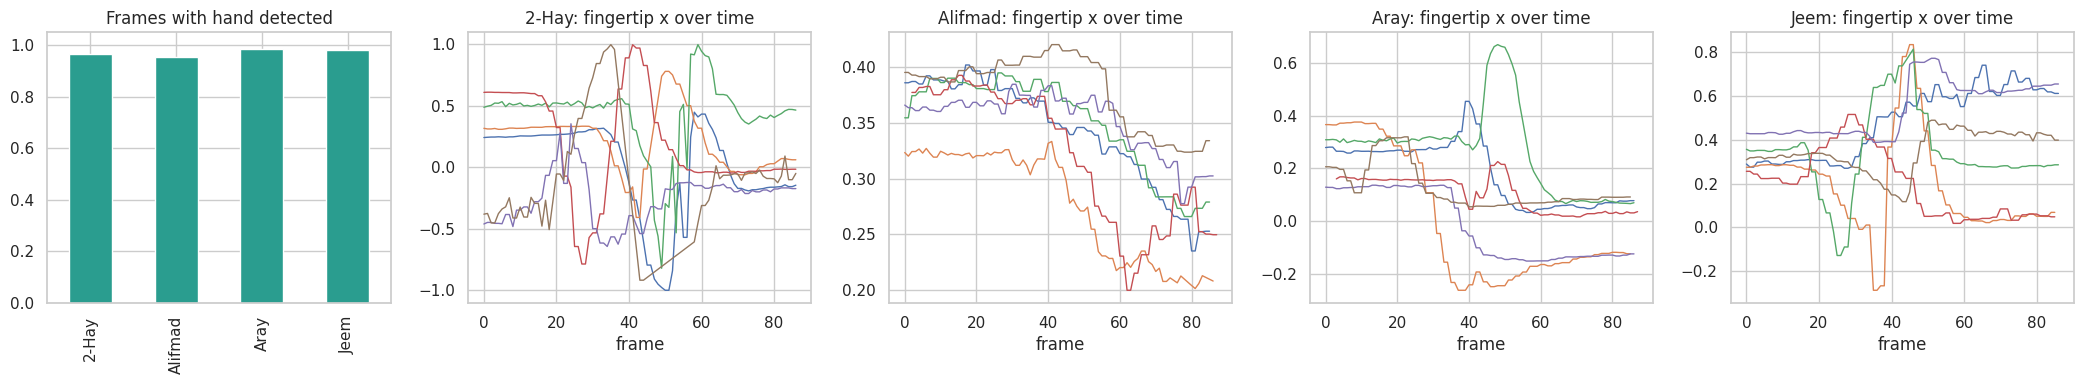

In [14]:
if X_dyn is not None:
    vids['detect_rate'] = M_dyn.mean(1)
    print('Detection rate per class:'); print(vids.groupby('label')['detect_rate'].mean().round(3).to_string())
    print('Videos with < 50% frames detected:', int((vids['detect_rate'] < 0.5).sum()), 'of', len(vids))
    print('Videos with 0 frames detected   :', int((vids['detect_rate'] == 0).sum()))

    fig, axes = plt.subplots(1, 5, figsize=(21, 4))
    vids.groupby('label')['detect_rate'].mean().plot(kind='bar', ax=axes[0], color='#2A9D8F'); axes[0].set_ylim(0, 1.05); axes[0].set_title('Frames with hand detected'); axes[0].set_xlabel('')
    for ax, c in zip(axes[1:], DYNAMIC):
        for i in vids.index[(vids['label'] == c) & (vids['split'] == 'train')][:6]:
            m = M_dyn[i]; tt = np.where(m)[0]
            ax.plot(tt, X_dyn[i, tt, 24], lw=1)   # index fingertip (landmark 8) x-coordinate, column 8*3+0
        ax.set_title(c + ': fingertip x over time'); ax.set_xlabel('frame')
    plt.tight_layout(); savefig('19_landmark_sequences.png'); plt.show()

**What it tells us:** the left panel shows how reliably MediaPipe finds the hand in each dynamic class, and the other panels show the normalized index-fingertip trajectory for several videos. If different classes produce visibly different curves, the landmark sequences carry enough signal for an LSTM to separate them.

## 8. Save everything

In [15]:
# processed metadata: one table for all modeling notebooks
vids['npz_index'] = np.arange(len(vids))
vids['processed_path'] = ''
cols = ['rel_path', 'processed_path', 'npz_index', 'label', 'class_id', 'media_type', 'subject', 'is_generated', 'split']
imgs['npz_index'] = -1
pm = pd.concat([imgs.reindex(columns=cols), vids.reindex(columns=cols)], ignore_index=True)
pm.to_csv(os.path.join(OUT, 'processed_metadata.csv'), index=False)

split_summary = pd.concat([pd.crosstab(pm['label'], pm['split'])[SPLITS], pm.groupby('label')['media_type'].first()], axis=1)
split_summary.to_csv(os.path.join(OUT, 'split_summary.csv'))

if X_dyn is not None:
    np.savez_compressed(os.path.join(OUT, 'dynamic_landmarks.npz'), X=X_dyn, mask=M_dyn, y=vids['class_id'].values,
                        split=vids['split'].values.astype(str), files=vids['rel_path'].values.astype(str))
    print('dynamic_landmarks.npz size (MB):', round(os.path.getsize(os.path.join(OUT, 'dynamic_landmarks.npz')) / 1e6, 1))

# optional: zip the processed images (~hundreds of MB) and keep a copy on Drive for the modeling phase
shutil.make_archive('/content/processed_images', 'zip', PROC)
print('processed_images.zip (MB):', round(os.path.getsize('/content/processed_images.zip') / 1e6))
# from google.colab import drive; drive.mount('/content/drive'); shutil.copy('/content/processed_images.zip', '/content/drive/MyDrive/')
pm.head()

dynamic_landmarks.npz size (MB): 4.9
processed_images.zip (MB): 254


,rel_path,processed_path,npz_index,label,class_id,media_type,subject,is_generated,split
0,1-Hay/s0317-10hay.JPG,train/1-Hay/s0317-10hay.jpg,-1,1-Hay,0,image,s0317,False,train
1,1-Hay/s0274-10hay.jpg,test/1-Hay/s0274-10hay.jpg,-1,1-Hay,0,image,s0274,False,test
2,1-Hay/s0261-10hay-Generated-5207.jpg,val/1-Hay/s0261-10hay-Generated-5207.jpg,-1,1-Hay,0,image,s0261,True,val
3,1-Hay/s0282-10hay.jpg,val/1-Hay/s0282-10hay.jpg,-1,1-Hay,0,image,s0282,False,val
4,1-Hay/s0267-10hay-Generated-106.jpg,val/1-Hay/s0267-10hay-Generated-106.jpg,-1,1-Hay,0,image,s0267,True,val


In [16]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)
hdr('Config'); print('IMG_SIZE', IMG_SIZE, '| split ratios', SPLIT_RATIOS, '| seed used for subject assignment', seed_used, '| padding fill (RGB):', fill_rgb.tolist())
hdr('Split'); print('Subjects per split:', pd.Series(subj2split).value_counts().to_dict(), '| worst per-class deviation:', round(dev, 3))
print('Images per split:', imgs['split'].value_counts().to_dict()); print('Original-only images per split:', orig_ct.sum().to_dict())
print('Generated share per split:', imgs.groupby('split')['is_generated'].mean().round(3).to_dict())
print('Per-class share min/max:'); print(pd.DataFrame({'min': share.min(), 'max': share.max()}).round(3).T.to_string())
print('Video split mode:', VIDEO_SPLIT_MODE); print(pd.crosstab(vids['label'], vids['split']).to_string())
hdr('Class weights'); print('Static min/max:', w_static.min(), w_static.max()); print('Dynamic:', {c: float(w_dyn[label2id[c]]) for c in DYNAMIC})
hdr('Normalization'); print('Train mean:', train_mean.round(4).tolist(), '| std:', train_std.round(4).tolist())
print('After normalization -> mean', round(float(normed.mean()), 3), 'std', round(float(normed.std()), 3))
hdr('Processed images'); print('Files written:', n_files, '| expected:', len(imgs))
hdr('Dynamic landmarks')
print('T =', T)
if X_dyn is not None:
    print('Tensor:', X_dyn.shape, '| overall detected-frame rate:', round(float(M_dyn.mean()), 3))
    print(vids.groupby('label')['detect_rate'].agg(['mean', 'min']).round(3).to_string())
    print('Videos <50% detected:', int((vids['detect_rate'] < 0.5).sum()), '| 0% detected:', int((vids['detect_rate'] == 0).sum()))
else:
    print('skipped')
hdr('Outputs'); print(sorted(os.listdir(OUT)))


Config
IMG_SIZE 224 | split ratios (0.7, 0.15, 0.15) | seed used for subject assignment 743 | padding fill (RGB): [175, 159, 153]

Split
Subjects per split: {'train': 59, 'val': 13, 'test': 12} | worst per-class deviation: 0.029
Images per split: {'train': 15062, 'test': 3238, 'val': 3060}
Original-only images per split: {'train': 2028, 'val': 439, 'test': 430}
Generated share per split: {'test': 0.867, 'train': 0.865, 'val': 0.857}
Per-class share min/max:
split  train    val   test
min    0.677  0.126  0.123
max    0.729  0.168  0.173
Video split mode: stratified random (no usable subject id in video filenames)
split    test  train  val
label                    
2-Hay      13     61   13
Alifmad    16     74   15
Aray       15     71   16
Jeem       15     69   15

Class weights
Static min/max: 0.868 1.1157
Dynamic: {'2-Hay': 1.127, 'Alifmad': 0.9291, 'Aray': 0.9683, 'Jeem': 0.9964}

Normalization
Train mean: [0.6892, 0.6248, 0.6012] | std: [0.2112, 0.23, 0.2432]
After normalization